# PortfolioPilot - 01 Cleaning and splitting

**Run the cells in order, top to bottom.** Install the package first (`pip install -e .` from the project root).

Rule for M3: the test sets are created in notebook 01 and then never explored. Every statistic, cap,
table and figure uses **training data only**.

Raw data in `data/raw/` is read-only. Everything written goes to `data/processed/`.

## Step 1 - Setting up

### Configuring paths and reproducibility

This cell loads the project settings from `config.yaml`: the input and output locations, the random seed, the SCF column mapping, the split sizes and the ETF universe. Keeping these settings in one place makes the remaining cells reproducible and easier to adapt to another environment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_pilot.config import Results, ensure_output_dirs, load_config

cfg = load_config()
ensure_output_dirs(cfg)
P, SEED = cfg["paths"], cfg["seed"]
results = Results(P["numbers_file"])    # every count quoted in the report; saved in the last cell
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(P["figures_dir"] / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Step 2 - Load the SCF and check its structure

### Reading and validating the SCF structure

The Survey of Consumer Finances contains five implicates for each household. This cell reads the summary extract, renames the selected variables to project-friendly names, verifies the expected columns and implicates, and records basic structural counts before cleaning.

In [2]:
from portfolio_pilot.clean import load_scf

full = load_scf(P["scf_file"], cfg["scf"]["columns"], results)
print(results["raw"])
full.head(10)

{'rows': 21800, 'columns': 362, 'households': 4360, 'implicates': [1, 2, 3, 4, 5]}


,household_id,record_id,weight,age,income,networth,liq,debt,equity,fin,yes_risk,no_risk,implicate
0,1,11,1241.701712,39,317351.351350,2434270.0,80300,250000.0,120150.0,215300,0,0,1
1,1,12,1247.038677,39,317351.351350,2208400.0,80300,250000.0,113800.0,229300,0,0,2
2,1,13,1234.428835,39,317351.351350,2128300.0,80300,250000.0,75300.0,209300,0,0,3
3,1,14,1267.530314,39,317351.351350,1742300.0,80300,250000.0,72800.0,212300,0,0,4
4,1,15,911.408367,39,317351.351350,1517300.0,80300,250000.0,73600.0,228300,0,0,5
5,2,21,13727.793587,69,66756.756757,3005160.0,8460,56000.0,689600.0,870460,0,0,1
6,2,22,14391.258395,69,65729.729730,2988260.0,8460,49000.0,83700.0,845460,0,0,2
7,2,23,13046.614667,69,66756.756757,2984260.0,8460,53000.0,83700.0,845460,0,0,3
8,2,24,14897.181445,69,65729.729730,2992170.0,8470,45000.0,83700.0,845470,0,0,4
9,2,25,16108.783691,69,67783.783784,3016280.0,8480,31000.0,84700.0,855480,0,0,5


## Step 3 - Cleaning: duplicates, missing values, impossible values

### Cleaning household records

This cell removes duplicate records, keeps implicate 1 as the one-row-per-household working file, checks missing and impossible values, and records genuine zero or negative financial values that should not be treated as data errors. It then derives the risk-willingness category and age band used later for stratification.

In [3]:
from portfolio_pilot.clean import clean_scf, quality_tables

# From this point we keep one row per household (implicate 1); the other implicates are checked in Step 5.
full, hh = clean_scf(full, cfg["scf"]["implicate"], results)
quality_table, genuine_table = quality_tables(results)

print("DATA-QUALITY CHECKS")
print("=" * 75)
display(quality_table)

print()
print("CLEANING SUMMARY")
print("=" * 75)
print(f"Rows before cleaning: {results['implicate_1']['rows']:,}")
print(f"Rows removed:         {results['errors']['rows_dropped']:,}")
print(f"Rows after cleaning:  {results['implicate_1']['rows_after_cleaning']:,}")

print()
print("VALID UNUSUAL VALUES")
print("=" * 75)
display(genuine_table)

hh.to_csv(P["processed_dir"] / "scf_clean.csv", index=False)

DATA-QUALITY CHECKS


,Check,Rows with problem,Status
0,Age is outside 18 to 100,0,PASS
1,Survey weight is zero or negative,0,PASS
2,Liquid assets are negative,0,PASS
3,Debt is negative,0,PASS
4,Equity is negative,0,PASS
5,Financial assets are negative,0,PASS
6,Equity exceeds financial assets,0,PASS
7,Liquid assets exceed financial assets,0,PASS
8,Both risk flags equal 1,0,PASS



CLEANING SUMMARY
Rows before cleaning: 4,360
Rows removed:         0
Rows after cleaning:  4,360

VALID UNUSUAL VALUES


,Value,Rows,Interpretation
0,income_zero,23,Valid value; retained for analysis
1,income_negative,0,Valid value; retained for analysis
2,networth_negative,330,Valid value; retained for analysis
3,fin_zero,53,Valid value; retained for analysis
4,debt_zero,1115,Valid value; retained for analysis


## Step 4 - Split train / validation / test (before any exploration)
Stratified on age band x risk willingness. Split by household, so implicates 2-5 can follow the same IDs later.

### Why stratify before splitting?

Before creating the partitions, we inspect the combination of age band and risk willingness. The chart shows whether some combinations are common or rare. Stratification helps keep this mix similar in the training, validation, and test sets.

HOUSEHOLDS BEFORE THE TRAIN/VALIDATION/TEST SPLIT


,No risk,Average risk,Above-average risk
age_band,,,
35-44,261,475,43
45-54,237,549,46
55-64,212,582,47
65-74,273,479,24
75+,218,268,18
<35,194,402,32


RISK-WILLINGNESS PERCENTAGES WITHIN EACH AGE BAND


,No risk,Average risk,Above-average risk
age_band,,,
35-44,33.5,61.0,5.5
45-54,28.5,66.0,5.5
55-64,25.2,69.2,5.6
65-74,35.2,61.7,3.1
75+,43.3,53.2,3.6
<35,30.9,64.0,5.1


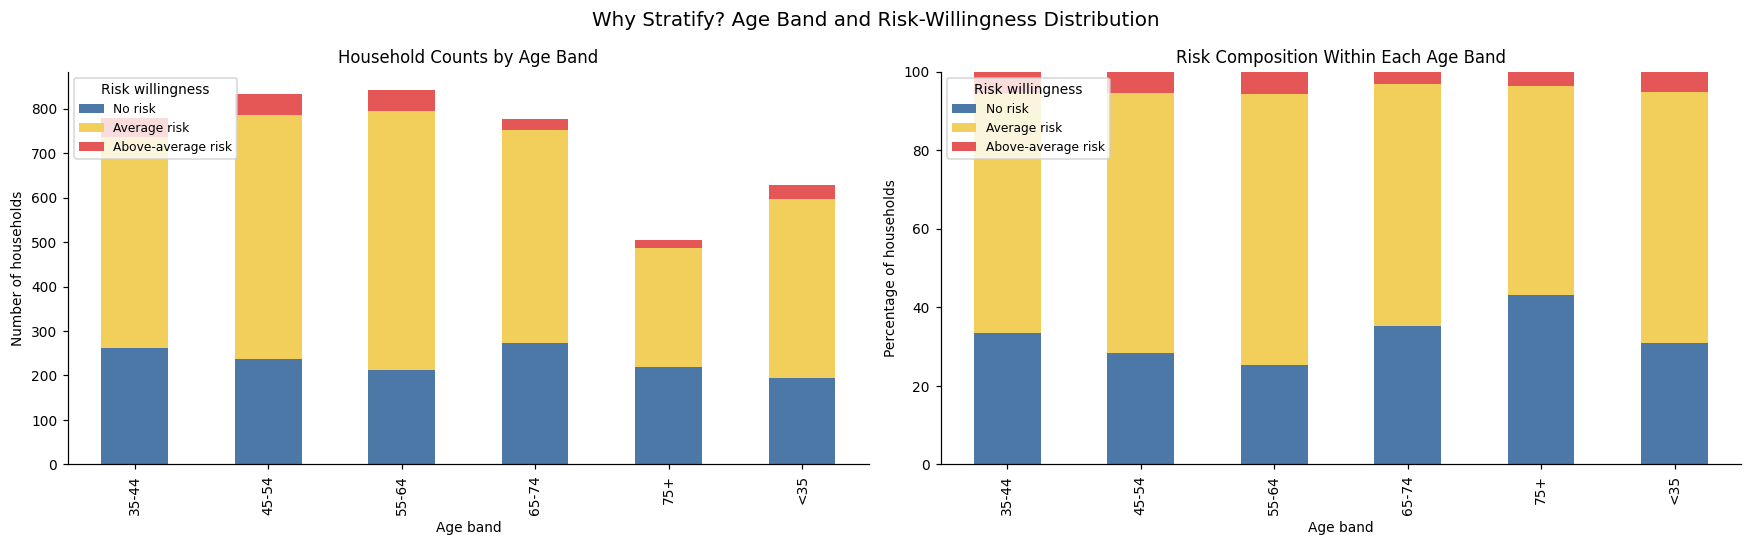

In [4]:
# Count households in each age-band and risk-willingness combination.
pre_split_table = pd.crosstab(hh["age_band"], hh["risk_willingness"]).reindex(columns=[0, 1, 2], fill_value=0)
pre_split_table.columns = ["No risk", "Average risk", "Above-average risk"]

print("HOUSEHOLDS BEFORE THE TRAIN/VALIDATION/TEST SPLIT")
print("=" * 75)
display(pre_split_table)

# Convert counts into percentages within each age band (each row adds up to 100 percent).
pre_split_percent = pre_split_table.div(pre_split_table.sum(axis=1), axis=0) * 100
print("=" * 75)
print("RISK-WILLINGNESS PERCENTAGES WITHIN EACH AGE BAND")
print("=" * 75)
display(pre_split_percent.round(1))

# Count and percentage charts side by side.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))
colors = ["#4C78A8", "#F2CF5B", "#E45756"]

# Left chart: the number of households in each group.
pre_split_table.plot(kind="bar", stacked=True, ax=axes[0], color=colors)
axes[0].set_title("Household Counts by Age Band")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Number of households")
axes[0].legend(title="Risk willingness", loc="upper left", fontsize=8)

# Right chart: the percentage composition of each age band.
pre_split_percent.plot(kind="bar", stacked=True, ax=axes[1], color=colors)
axes[1].set_title("Risk Composition Within Each Age Band")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Percentage of households")
axes[1].set_ylim(0, 100)
axes[1].legend(title="Risk willingness", loc="upper left", fontsize=8)

fig.suptitle("Why Stratify? Age Band and Risk-Willingness Distribution", fontsize=13)
plt.tight_layout()
plt.show()

### Creating leakage-safe data partitions

The household IDs are split into training, validation, and test partitions before exploratory analysis. Stratification preserves the joint distribution of age band and risk willingness, while the household-level split prevents rows from the same household from crossing partitions. Only the training partition is used to fit later transformations and clustering decisions.

In [5]:
from portfolio_pilot.split import save_split_ids, split_households

parts = split_households(hh, cfg["scf"]["split"], SEED, cfg["scf"]["min_stratum_size"], results)
save_split_ids(parts, P["processed_dir"] / "scf_split_ids.csv")
results["split"]

{'n_strata': 18,
 'train_households': 3052,
 'train_weight_share': np.float64(0.7033403995202065),
 'val_households': 654,
 'val_weight_share': np.float64(0.1441687614754587),
 'test_households': 654,
 'test_weight_share': np.float64(0.15249083900433474)}

## Step 5 - Implicate structure check

### Checking SCF implicates

Each household should have five implicate rows. This cell checks that structure within the training households and measures how often the financial variables differ across implicates. The results help document the uncertainty represented by the SCF replicate records without allowing test data into the analysis.

In [6]:
# Verify five implicates per training household and quantify variation across the replicate records.
tr_full = full[full["household_id"].isin(parts["train"]["household_id"])]   # all implicates of the training households
g = tr_full.groupby("household_id")
results.note("implicates", "train_households_without_5_rows", int((g.size() != 5).sum()))
for c in ["income", "networth", "liq", "debt"]:
    # share of training households whose value differs across their five implicates
    results.note("implicates", f"share_where_{c}_varies", float((g[c].nunique() > 1).mean().round(2)))
results["implicates"]

{'train_households_without_5_rows': 0,
 'share_where_income_varies': 0.61,
 'share_where_networth_varies': 0.91,
 'share_where_liq_varies': 0.44,
 'share_where_debt_varies': 0.43}

**Why this check matters.**

We've used implicate 1 as the main one-row-per-household dataset for clustering. This cell confirms that:

* The training households still have all five implicates available in full.
* The financial variables can differ across implicates.
* Those differences should be recognized as survey uncertainty rather than automatically treated as errors.
* The full dataset is used here instead of only `hh` because `hh` contains just implicate 1, while `full` contains all five implicates.

## Step 6 - Load the ETF data and check its structure
If the file is missing, run `python -m portfolio_pilot.download_etf` from the project root.

### Loading and checking ETF prices

This cell loads the ETF price file, standardizes dates and ticker names, checks the expected universe, and records duplicate, missing, and non-positive price issues before returns are calculated.

In [7]:
from portfolio_pilot.clean import load_etf_prices

TICKERS = cfg["etf"]["tickers"]
wide = load_etf_prices(P["etf_prices_file"], TICKERS, results)
print(results["etf_raw"])
wide.head()

{'rows_trading_days': 2514, 'columns': 9, 'date_range': ['2016-01-04', '2025-12-31'], 'tickers_missing': [], 'unexpected_columns': [], 'missing_by_ticker': {'AGG': 0, 'DBC': 0, 'GLD': 0, 'SPY': 0, 'TIP': 0, 'TLT': 0, 'VEA': 0, 'VNQ': 0, 'VWO': 0}, 'first_valid_date': {'AGG': '2016-01-04', 'DBC': '2016-01-04', 'GLD': '2016-01-04', 'SPY': '2016-01-04', 'TIP': '2016-01-04', 'TLT': '2016-01-04', 'VEA': '2016-01-04', 'VNQ': '2016-01-04', 'VWO': '2016-01-04'}}


,AGG,DBC,GLD,SPY,TIP,TLT,VEA,VNQ,VWO
date,,,,,,,,,
2016-01-04,79.657753,11.210503,102.889999,169.051773,80.085342,89.580688,26.352303,51.486614,23.626696
2016-01-05,79.694633,11.100595,103.180000,169.337692,80.034424,89.219238,26.323160,52.480160,23.678740
2016-01-06,79.997086,10.923054,104.669998,167.201645,80.288979,90.421509,25.842299,52.336346,23.254967
2016-01-07,79.989677,10.872327,106.150002,163.190186,80.223503,90.583824,25.354160,51.316669,22.504093
2016-01-08,80.166809,10.821601,105.680000,161.398956,80.288979,90.989456,25.040878,50.630371,22.303368


## Step 7 - Clean ETF prices, compute returns, split by time

### Cleaning ETF prices and creating return partitions

Prices are reshaped to one row per trading day, isolated gaps are handled, and daily returns are computed. The time-based train, validation, and test periods preserve chronology; ETF exploration and any fitted transformations use only the training period.

In [8]:
from portfolio_pilot.clean import clean_etf_prices, etf_wide_to_long
from portfolio_pilot.features import daily_log_returns
from portfolio_pilot.split import split_returns_by_time

prices = clean_etf_prices(etf_wide_to_long(wide), TICKERS, results)
ret = daily_log_returns(prices)

# train: 2016 to 2021 | validation: 2022 to 2023 | test: 2024 to 2025
etf_parts = split_returns_by_time(ret, cfg["etf"]["train_end"], cfg["etf"]["val_end"], results)
for name, d in etf_parts.items():
    d.to_csv(P["processed_dir"] / f"etf_returns_{name}.csv")

# Show the cleaning counts and the split summary in readable tables.
etf_summary = pd.DataFrame([{"Section": "Cleaning", "Metric": key, "Value": value}
                            for key, value in results["etf"].items()])
etf_split_summary = pd.DataFrame([{"Partition": name, **values} for name, values in results["etf_split"].items()])
print("ETF CLEANING SUMMARY")
print("=" * 75)
display(etf_summary)
print("ETF TIME-BASED SPLIT SUMMARY")
print("=" * 75)
display(etf_split_summary)

ETF CLEANING SUMMARY


,Section,Metric,Value
0,Cleaning,rows,22626
1,Cleaning,tickers_missing,[]
2,Cleaning,duplicate_date_ticker,0
3,Cleaning,missing_prices,0
4,Cleaning,non_positive_prices,0
5,Cleaning,missing_days_by_ticker,{}
6,Cleaning,cells_forward_filled,0
7,Cleaning,trading_days,2514
8,Cleaning,date_range,"[2016-01-04, 2025-12-31]"


ETF TIME-BASED SPLIT SUMMARY


,Partition,days,from,to
0,train,1510,2016-01-05,2021-12-31
1,val,501,2022-01-03,2023-12-29
2,test,502,2024-01-02,2025-12-31


## Save the numbers quoted in the report

In [9]:
from portfolio_pilot.config import PROJECT_ROOT

results.save()
print("Saved", P["numbers_file"].relative_to(PROJECT_ROOT).as_posix())

Saved reports/numbers.json
